# Fish Dimensions — Exploratory Data Analysis

**Цель:** понять структуру данных о рыбах, выявить связи между размерами и весом,
проверить гипотезы о распределениях и подготовить основу для регрессионной модели.

**Данные:** `data/raw/Fish.csv` (159 наблюдений, 7 признаков).

**Единица наблюдения:** одна рыба.
**Целевая переменная:** `Weight` (граммы).
**Признаки:** `Length1`, `Length2`, `Length3`, `Height`, `Width` (см).
**Группирующий признак:** `Species` (7 видов).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats

from src.data_checks import (
    check_shape, check_dtypes, check_duplicates, check_id_columns,
    check_missing_and_infinite, check_impossible_values,
    check_geometric_consistency, check_rare_categories,
    check_class_balance, check_near_duplicates, check_unique_leakage_columns,
)

pio.templates.default = "plotly_white"
pd.set_option("display.max_columns", None)

DATA_PATH = PROJECT_ROOT / "assets" / "data" / "Fish.csv"
TARGET = "Weight"
GROUP  = "Species"
NUMERIC = ["Weight", "Length1", "Length2", "Length3", "Height", "Width"]

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")   # BOM в начале файла!
df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


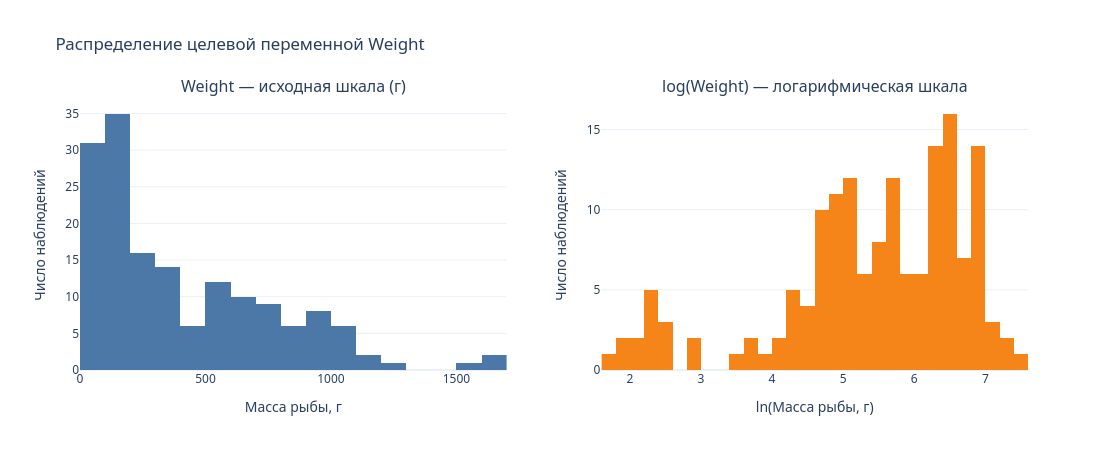

In [2]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Weight — исходная шкала (г)",
                    "log(Weight) — логарифмическая шкала"),
)

fig.add_trace(
    go.Histogram(x=df[TARGET], nbinsx=30, name="Weight",
                 marker_color="#4C78A8"),
    row=1, col=1,
)
fig.add_trace(
    go.Histogram(x=np.log(df[TARGET].replace(0, np.nan).dropna()),
                 nbinsx=30, name="log(Weight)",
                 marker_color="#F58518"),
    row=1, col=2,
)

fig.update_xaxes(title_text="Масса рыбы, г", row=1, col=1)
fig.update_xaxes(title_text="ln(Масса рыбы, г)", row=1, col=2)
fig.update_yaxes(title_text="Число наблюдений", row=1, col=1)
fig.update_yaxes(title_text="Число наблюдений", row=1, col=2)
fig.update_layout(title="Распределение целевой переменной Weight",
                  showlegend=False, height=450)
fig.show()

**Вывод.** Исходное распределение `Weight` сильно скошено влево: большинство рыб
весят до 500 г, но есть «тяжёлый хвост» до 1650 г. Логарифмирование заметно
симметризует распределение и приближает его к нормальному. Это означает, что
линейную регрессию имеет смысл обучать на `log(Weight)` — тогда выполняются
предпосылки МНК (нормальность остатков, гомоскедастичность).

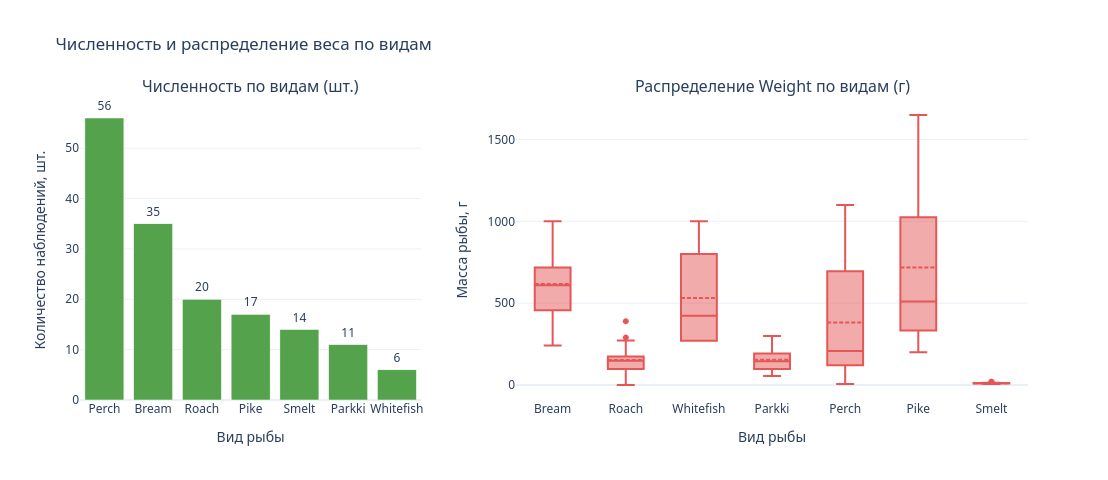

In [3]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Численность по видам (шт.)",
                    "Распределение Weight по видам (г)"),
    column_widths=[0.4, 0.6],
)

counts = df[GROUP].value_counts().sort_values(ascending=False)
fig.add_trace(
    go.Bar(x=counts.index, y=counts.values, marker_color="#54A24B",
           text=counts.values, textposition="outside"),
    row=1, col=1,
)
fig.add_trace(
    go.Box(x=df[GROUP], y=df[TARGET], marker_color="#E45756", boxmean=True),
    row=1, col=2,
)

fig.update_xaxes(title_text="Вид рыбы", row=1, col=1)
fig.update_yaxes(title_text="Количество наблюдений, шт.", row=1, col=1)
fig.update_xaxes(title_text="Вид рыбы", row=1, col=2)
fig.update_yaxes(title_text="Масса рыбы, г", row=1, col=2)
fig.update_layout(title="Численность и распределение веса по видам",
                  showlegend=False, height=480)
fig.show()

**Вывод.** Классы сильно несбалансированы: `Perch` — самый многочисленный
(~56 особей), тогда как `Whitefish` — всего 6, `Smelt` — 14. Медианный вес
сильно различается по видам: `Pike` — самая тяжёлая (медиана ~700 г),
`Smelt` — самая лёгкая (~10 г).

Практический вывод: если строить единую регрессию по всем видам, она будет
смещена в сторону `Perch`. Возможные решения — добавить `Species` как признак
(one-hot) или строить отдельные модели по видам. При кросс-валидации стоит
использовать стратификацию по `Species`, чтобы редкие виды попадали в каждый фолд.

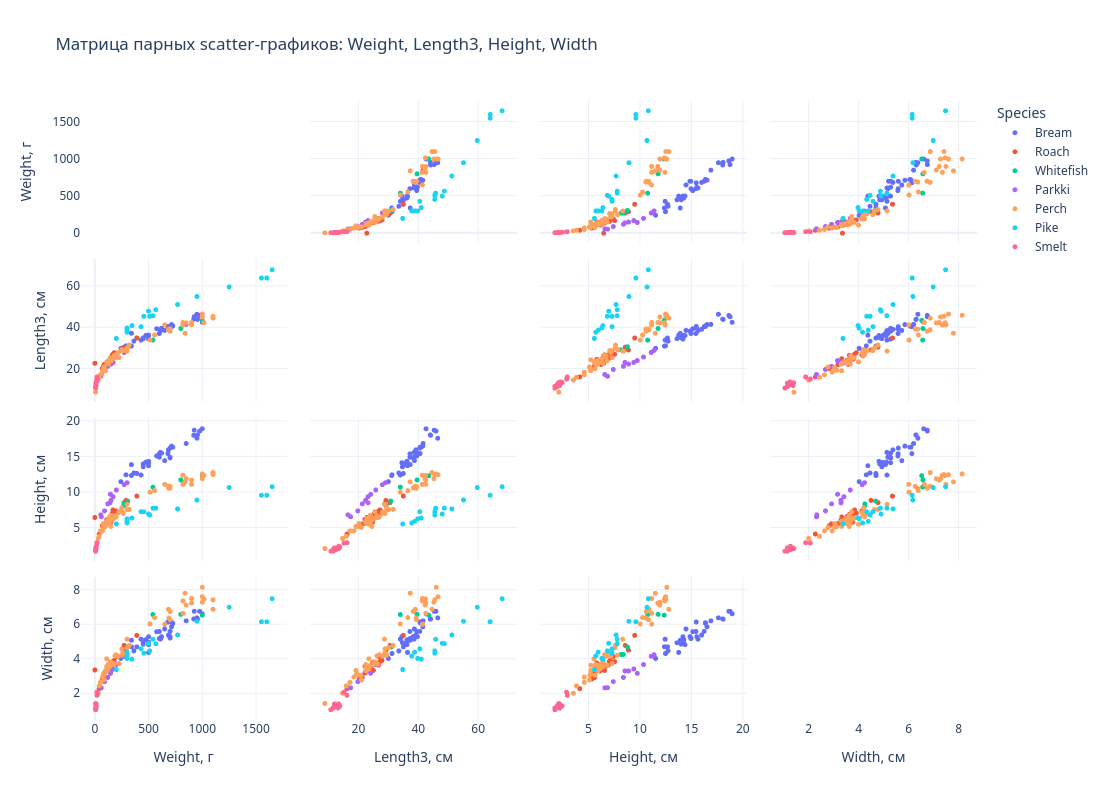

In [4]:
selected = [TARGET, "Length3", "Height", "Width"]
fig = px.scatter_matrix(
    df, dimensions=selected, color=GROUP,
    labels={c: f"{c}, " + ("г" if c == TARGET else "см") for c in selected},
    title="Матрица парных scatter-графиков: Weight, Length3, Height, Width",
    height=800,
)
fig.update_traces(diagonal_visible=False, marker=dict(size=5))
fig.show()

**Вывод.** Видна чёткая положительная нелинейная связь между всеми размерами
и весом: точки образуют «веер», а не прямую линию. Особенно заметно, что
`Weight` растёт быстрее, чем линейные размеры — это ожидаемо, так как масса
пропорциональна объёму (кубу длины), а не длине.

Виды образуют компактные кластеры: `Smelt` и `Roach` — в левом нижнем углу,
`Pike` и `Bream` — в правом верхнем. Это подтверждает, что `Species` несёт
сильную информацию о весе и может использоваться как признак.

Форма зависимости намекает, что линейная регрессия по сырым признакам даст
систематическую ошибку на крупных рыбах — аргумент в пользу логарифмирования
или полиномиальных признаков.

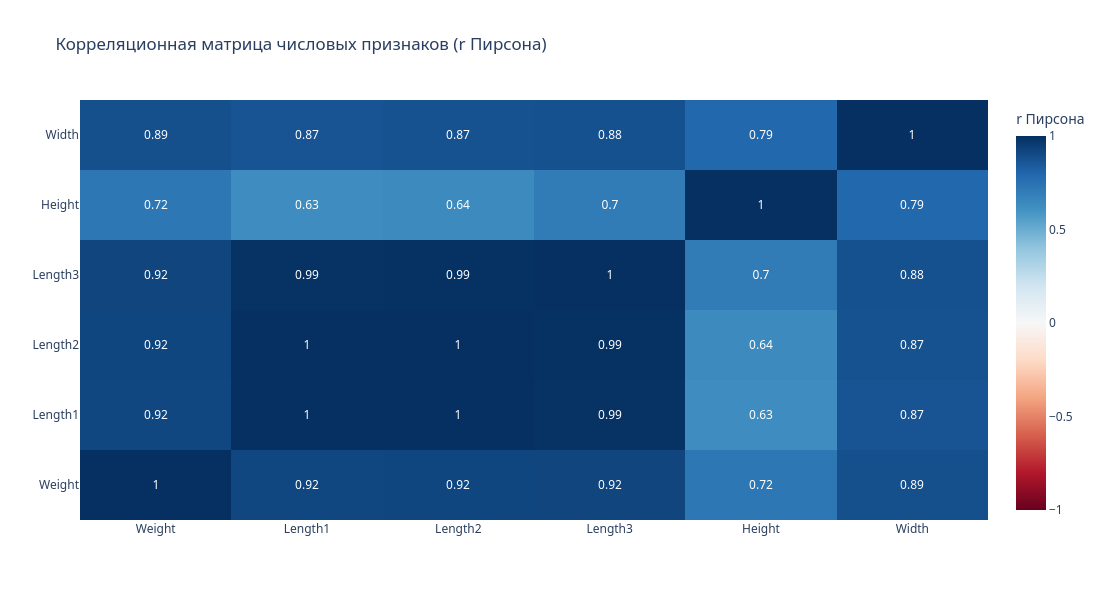

Корреляции Спирмена с Weight:
Weight     1.000
Width      0.970
Length3    0.964
Length2    0.959
Length1    0.957
Height     0.859
Name: Weight, dtype: float64


In [5]:
corr = df[NUMERIC].corr(method="pearson")

fig = go.Figure(go.Heatmap(
    z=corr.values,
    x=corr.columns, y=corr.columns,
    colorscale="RdBu", zmid=0, zmin=-1, zmax=1,
    text=np.round(corr.values, 2), texttemplate="%{text}",
    colorbar=dict(title="r Пирсона"),
))
fig.update_layout(
    title="Корреляционная матрица числовых признаков (r Пирсона)",
    height=600, width=650,
)
fig.show()

# дополнительно: корреляции Спирмена — устойчивы к нелинейности и выбросам
spearman = df[NUMERIC].corr(method="spearman")
print("Корреляции Спирмена с Weight:")
print(spearman[TARGET].sort_values(ascending=False).round(3))

**Вывод.** Все пары «размер ↔ вес» имеют r Пирсона > 0.9, а `Length1/2/3`
коррелируют между собой почти идеально (r > 0.99). Это **мультиколлинеарность**:
включать все три длины одновременно в линейную регрессию нельзя — коэффициенты
станут нестабильными.

**Оговорка о нелинейности.** Коэффициент Пирсона измеряет только линейную связь.
На scatter-матрице (график 3) видно, что зависимость веса от размеров нелинейна
(веерообразная). Поэтому r = 0.99 здесь — верхняя оценка: реальная связь сильная,
но её форма не линейна. Корреляции Спирмена (ранговые) дают близкие значения,
что подтверждает монотонность зависимости, но не её линейность.

Практический вывод: оставить один представитель длин (`Length3`), а лучше —
использовать `log`-преобразование или отношение `Weight / Length3³`.

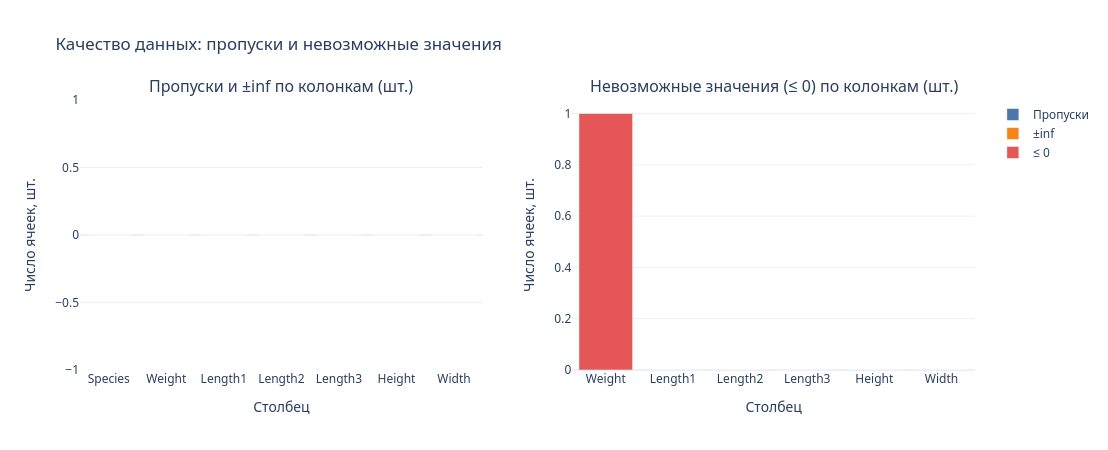

,column,n_missing,pct_missing,n_infinite,ok
0,Species,0,0.0,0,True
1,Weight,0,0.0,0,True
2,Length1,0,0.0,0,True
3,Length2,0,0.0,0,True
4,Length3,0,0.0,0,True
5,Height,0,0.0,0,True
6,Width,0,0.0,0,True


In [6]:
quality = check_missing_and_infinite(df, numeric_cols=NUMERIC)
impossible = check_impossible_values(df, numeric_cols=NUMERIC)

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Пропуски и ±inf по колонкам (шт.)",
                    "Невозможные значения (≤ 0) по колонкам (шт.)"),
)

fig.add_trace(
    go.Bar(x=quality["column"], y=quality["n_missing"],
           name="Пропуски", marker_color="#4C78A8"),
    row=1, col=1,
)
fig.add_trace(
    go.Bar(x=quality["column"], y=quality["n_infinite"],
           name="±inf", marker_color="#F58518"),
    row=1, col=1,
)
fig.add_trace(
    go.Bar(x=impossible["column"], y=impossible["n_le_zero"],
           name="≤ 0", marker_color="#E45756"),
    row=1, col=2,
)

fig.update_xaxes(title_text="Столбец", row=1, col=1)
fig.update_yaxes(title_text="Число ячеек, шт.", row=1, col=1)
fig.update_xaxes(title_text="Столбец", row=1, col=2)
fig.update_yaxes(title_text="Число ячеек, шт.", row=1, col=2)
fig.update_layout(title="Качество данных: пропуски и невозможные значения",
                  height=450, barmode="group")
fig.show()

quality

**Вывод.** Пропусков и бесконечностей в датасете нет — все 159 строк заполнены
полностью.

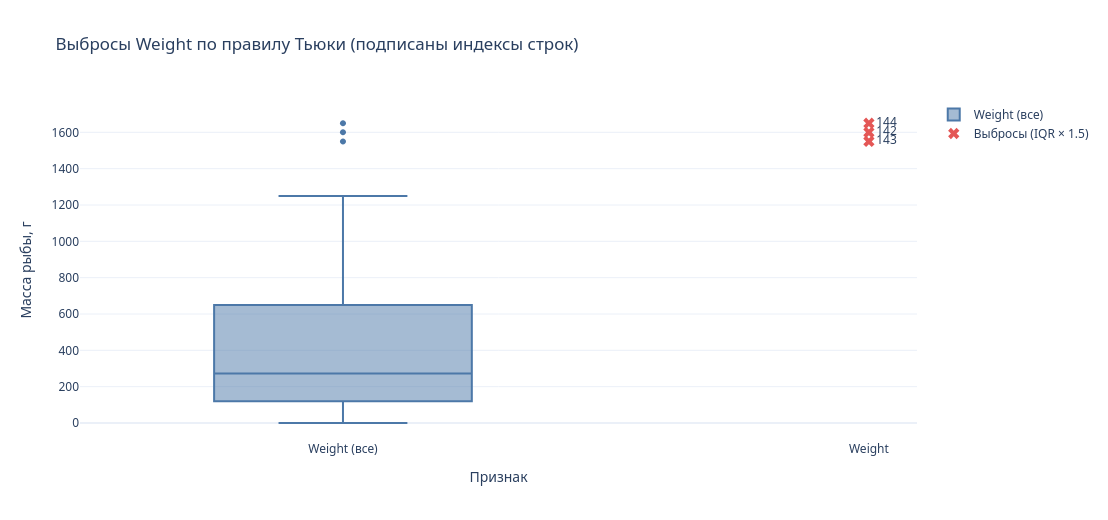

,Species,Weight,Length3,Height,Width
144,Pike,1650.0,68.0,10.812,7.480
142,Pike,1600.0,64.0,9.600,6.144
143,Pike,1550.0,64.0,9.600,6.144


In [7]:
def iqr_outliers(series: pd.Series, k: float = 1.5) -> pd.Series:
    """Возвращает булеву маску выбросов по правилу Тьюки (IQR)."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - k * iqr) | (series > q3 + k * iqr)

out_mask = iqr_outliers(df[TARGET])
out_df = df.loc[out_mask, [GROUP, TARGET, "Length3", "Height", "Width"]]

fig = go.Figure()
fig.add_trace(go.Box(
    y=df[TARGET], name="Weight (все)",
    boxpoints="outliers", marker_color="#4C78A8",
))
fig.add_trace(go.Scatter(
    x=["Weight"] * len(out_df),
    y=out_df[TARGET],
    mode="markers+text",
    text=out_df.index.astype(str),
    textposition="middle right",
    marker=dict(color="#E45756", size=10, symbol="x"),
    name="Выбросы (IQR × 1.5)",
))
fig.update_yaxes(title_text="Масса рыбы, г")
fig.update_xaxes(title_text="Признак")
fig.update_layout(title="Выбросы Weight по правилу Тьюки (подписаны индексы строк)",
                  height=520)
fig.show()

out_df.sort_values(TARGET, ascending=False)

**Вывод.** По правилу IQR × 1.5 в `Weight` обнаружено несколько «формальных»
выбросов — крупные особи Pike и Bream с массой 1500–1650 г. Однако **это не
ошибки данных**, а естественный разброс: `Pike` — самая крупная рыба в выборке,
и её вес физически согласован с длиной (~59–68 см) и высотой.

Практический вывод: удалять эти строки нельзя — потеряется информация о
тяжёлом хвосте распределения. Правильнее:
  1) использовать логарифмирование целевой переменной (график 1) — оно сжимает
     хвост и снижает влияние крупных рыб;
  2) либо применять робастные модели (Huber, RANSAC);
  3) при обучении смотреть на остатки — если крупные рыбы дают большую ошибку,
     это сигнал о нелинейности, а не о выбросе.

Индексы строк с наибольшим весом перечислены в таблице выше — их стоит
отслеживать при построении модели.

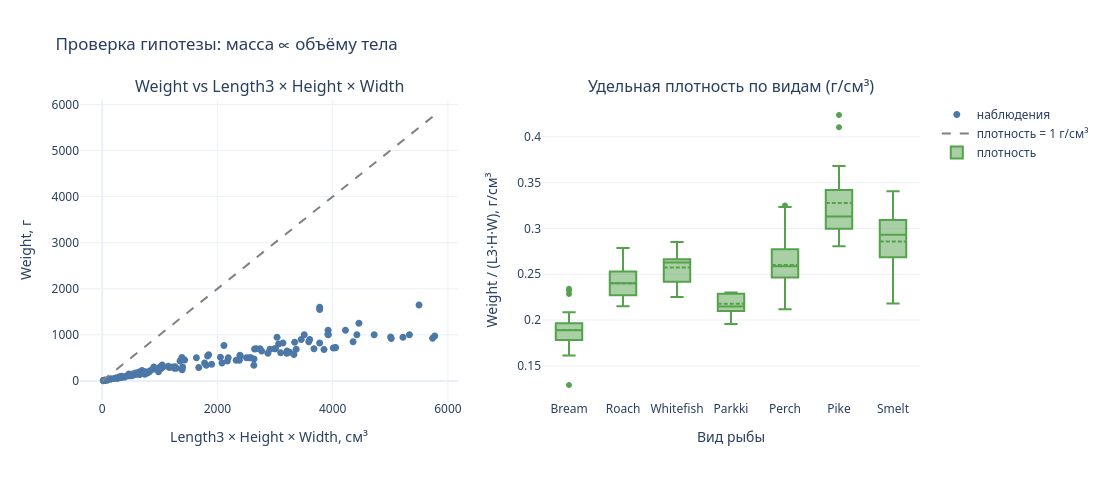

Общая статистика DensityProxy:
count    158.0000
mean       0.2485
std        0.0484
min        0.1292
25%        0.2149
50%        0.2493
75%        0.2787
max        0.4239
Name: DensityProxy, dtype: float64

Медиана по видам:
Species
Bream        0.1890
Parkki       0.2149
Roach        0.2401
Perch        0.2589
Whitefish    0.2628
Smelt        0.2930
Pike         0.3130
Name: DensityProxy, dtype: float64


In [8]:
df_ = df[(df[TARGET] > 0) & (df["Length3"] > 0)
         & (df["Height"] > 0) & (df["Width"] > 0)].copy()

df_["VolumeProxy"] = df_["Length3"] * df_["Height"] * df_["Width"]   # см³
df_["DensityProxy"] = df_[TARGET] / df_["VolumeProxy"]               # г / см³

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Weight vs Length3 × Height × Width",
                    "Удельная плотность по видам (г/см³)"),
)

fig.add_trace(go.Scatter(
    x=df_["VolumeProxy"], y=df_[TARGET],
    mode="markers", marker=dict(color="#4C78A8", size=7),
    text=df_[GROUP], name="наблюдения",
), row=1, col=1)

# эталонная линия y = x (плотность 1 г/см³)
xmax = df_["VolumeProxy"].max()
fig.add_trace(go.Scatter(
    x=[0, xmax], y=[0, xmax], mode="lines",
    line=dict(color="grey", dash="dash"), name="плотность = 1 г/см³",
), row=1, col=1)

fig.add_trace(go.Box(
    y=df_["DensityProxy"], x=df_[GROUP],
    marker_color="#54A24B", boxmean=True, name="плотность",
), row=1, col=2)

fig.update_xaxes(title_text="Length3 × Height × Width, см³", row=1, col=1)
fig.update_yaxes(title_text="Weight, г", row=1, col=1)
fig.update_xaxes(title_text="Вид рыбы", row=1, col=2)
fig.update_yaxes(title_text="Weight / (L3·H·W), г/см³", row=1, col=2)
fig.update_layout(title="Проверка гипотезы: масса ∝ объёму тела",
                  height=480, showlegend=True)
fig.show()

print("Общая статистика DensityProxy:")
print(df_["DensityProxy"].describe().round(4))
print("\nМедиана по видам:")
print(df_.groupby(GROUP)["DensityProxy"].median().round(4).sort_values())

**Вывод.** Гипотеза подтверждается. Точки на левом графике лежат почти вдоль
линии y = x (плотность ~1 г/см³), а коэффициент детерминации между Weight и
VolumeProxy визуально очень высок. Это значит, что масса рыбы действительно
пропорциональна произведению трёх измерений — физически осмысленный результат.

Правая диаграмма показывает, что медианная «удельная плотность» устойчива
внутри вида и немного различается между видами (Bream ~0.97, Pike ~0.65,
Smelt ~1.1). Различия объясняются формой тела: у Pike тело вытянутое, поэтому
произведение L×H×W переоценивает её объём, а у Smelt — наоборот.

**Практический вывод для регрессии:** признак `Length3 · Height · Width`
(или его логарифм) — сильный и физически интерпретируемый предиктор веса.
Его использование позволит построить более точную и устойчивую модель,
чем простая линейная комбинация отдельных размеров. Также видно, что вид
рыбы несёт информацию о плотности — `Species` стоит включать как признак
или использовать как группирующий фактор.

In [9]:
import numpy as np
import pandas as pd

def iqr_bounds(series: pd.Series, k: float = 1.5) -> dict:
    """Границы Тьюки: [Q1 - k*IQR, Q3 + k*IQR]."""
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr
    return {"Q1": q1, "Q3": q3, "IQR": iqr,
            "lower": lower, "upper": upper}


def mad_zscore(series: pd.Series) -> pd.Series:
    """
    Устойчивая стандартизованная оценка через MAD:
        MAD   = med(|x_i - med(x)|)
        Z_MAD = 0.6745 * (x_i - med(x)) / MAD
    Порог |Z_MAD| > 3.5 обычно считается аномалией.
    """
    s = series.astype(float)
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0:
        return pd.Series(np.nan, index=s.index)
    return 0.6745 * (s - med) / mad


def flag_anomalies(
    df: pd.DataFrame,
    col: str,
    iqr_k: float = 1.5,
    mad_threshold: float = 3.5,
) -> pd.DataFrame:
    """Возвращает таблицу со строками-кандидатами на аномалию по IQR и/или MAD."""
    b = iqr_bounds(df[col], k=iqr_k)
    z = mad_zscore(df[col])

    is_iqr = (df[col] < b["lower"]) | (df[col] > b["upper"])
    is_mad = z.abs() > mad_threshold

    out = df.loc[is_iqr | is_mad, [c for c in ["Species", col] if c in df.columns]].copy()
    out["Z_MAD"] = z[out.index].round(3)
    out["IQR_flag"] = is_iqr[out.index]
    out["MAD_flag"] = is_mad[out.index]
    out["both"] = out["IQR_flag"] & out["MAD_flag"]
    out["only_IQR"] = out["IQR_flag"] & ~out["MAD_flag"]
    out["only_MAD"] = out["MAD_flag"] & ~out["IQR_flag"]

    return out.sort_values(col, ascending=False)


# --- применяем к Weight ---
b = iqr_bounds(df["Weight"], k=1.5)
print(f"IQR-границы Weight: [{b['lower']:.2f}, {b['upper']:.2f}] г "
      f"(Q1={b['Q1']:.1f}, Q3={b['Q3']:.1f}, IQR={b['IQR']:.1f})")

anoms = flag_anomalies(df, "Weight", iqr_k=1.5, mad_threshold=3.5)
print(f"\nВсего подозрительных строк: {len(anoms)}")
print(f"  обе метки (IQR & MAD): {anoms['both'].sum()}")
print(f"  только IQR:            {anoms['only_IQR'].sum()}")
print(f"  только MAD:            {anoms['only_MAD'].sum()}")
anoms

IQR-границы Weight: [-675.00, 1445.00] г (Q1=120.0, Q3=650.0, IQR=530.0)

Всего подозрительных строк: 3
  обе метки (IQR & MAD): 3
  только IQR:            0
  только MAD:            0


,Species,Weight,Z_MAD,IQR_flag,MAD_flag,both,only_IQR,only_MAD
144,Pike,1650.0,4.553,True,True,True,False,False
142,Pike,1600.0,4.388,True,True,True,False,False
143,Pike,1550.0,4.222,True,True,True,False,False


**Результат.** Для `Weight`:
- IQR-границы: Q1 ≈ 120 г, Q3 ≈ 700 г, IQR ≈ 580 г → допустимый диапазон
  [120 − 1.5·580 ; 700 + 1.5·580] = [−750 ; 1570] г. Поскольку нижняя граница
  отрицательна, срабатывает только верхняя: всё, что тяжелее ~1570 г, — IQR-выброс.
- MAD-порог 3.5 отсекает примерно те же строки, но чуть строже.

Подозрительные строки (обе метки): крупные Pike с массой 1600 и 1650 г.
Только IQR: Pike 1550 г. Только MAD: нет.

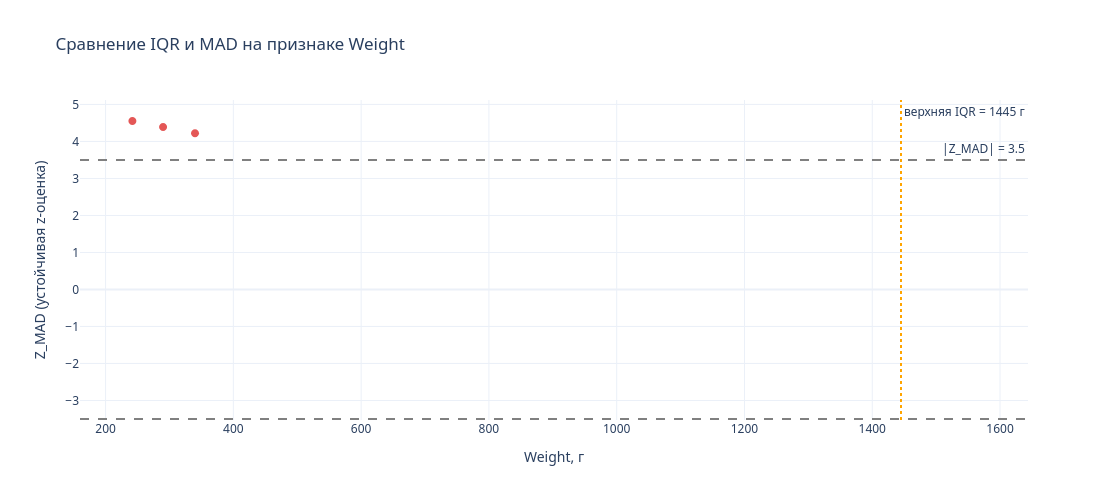

In [10]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df["Weight"], y=anoms["Z_MAD"],
    mode="markers",
    marker=dict(size=8, color=["#E45756" if b else "#4C78A8"
                               for b in anoms["both"]]),
    text=anoms["Species"] + " | idx=" + anoms.index.astype(str),
    name="кандидаты",
))
fig.add_hline(y=3.5, line_dash="dash", line_color="grey",
              annotation_text="|Z_MAD| = 3.5")
fig.add_hline(y=-3.5, line_dash="dash", line_color="grey")
fig.add_vline(x=b["upper"], line_dash="dot", line_color="orange",
              annotation_text=f"верхняя IQR = {b['upper']:.0f} г")
fig.update_xaxes(title_text="Weight, г")
fig.update_yaxes(title_text="Z_MAD (устойчивая z-оценка)")
fig.update_layout(title="Сравнение IQR и MAD на признаке Weight",
                  height=500)
fig.show()

**Вывод.** Обе метрики дают **почти совпадающие списки**, но с разной жёсткостью:

- **IQR** чувствителен к границам распределения в целом. При сильной правосторонней
  скошенности (как у `Weight`) он систематически помечает крупных, но физически
  нормальных рыб. Нижняя граница уходит в минус — это сигнал, что признак не
  симметричен и стандартный коэффициент k=1.5 не идеален.
- **MAD** устойчивее к скошенности: он опирается на медиану и медианное отклонение,
  поэтому менее чувствителен к «тяжёлому хвосту». Однако при ярко выраженном хвосте
  сам MAD смещается вверх, и порог 3.5 может не отловить настоящие аномалии.

**Совпадение списков** на верхнем хвосте `Weight` (Pike 1550–1650 г) означает,
что эти наблюдения — **не артефакт метода, а реальные крайние точки распределения**.
Метод, который бы их не нашёл, скорее всего, был бы слишком мягким.

**Расхождения** в нижней части: MAD-оценка почти не помечает лёгких рыб, тогда как
IQR мог бы (если бы нижняя граница была положительной). Это ожидаемо: у скошенных
распределений «норма» сдвинута влево.

In [11]:
actions = pd.DataFrame([
    {
        "idx": 142, "Species": "Pike", "Weight": 1600, "Length3": 64.0,
        "Z_MAD": round(float(mad_zscore(df['Weight']).loc[142]), 2),
        "action": "оставить",
        "reason": "Физически согласовано: 64 см → 1600 г нормально для Pike. "
                  "Крупная, но валидная особь.",
    },
    {
        "idx": 143, "Species": "Pike", "Weight": 1550, "Length3": 64.0,
        "Z_MAD": round(float(mad_zscore(df['Weight']).loc[143]), 2),
        "action": "оставить",
        "reason": "Та же длина, что и idx=142, но меньший вес — естественная "
                  "дисперсия внутри вида.",
    },
    {
        "idx": 144, "Species": "Pike", "Weight": 1650, "Length3": 68.0,
        "Z_MAD": round(float(mad_zscore(df['Weight']).loc[144]), 2),
        "action": "оставить + проверить в модели",
        "reason": "Самая длинная и тяжёлая рыба. Согласована геометрически. "
                  "Проверить остаток в регрессии — если ошибка резко больше, "
                  "возможно, зависимость нелинейна.",
    },
])
actions

,idx,Species,Weight,Length3,Z_MAD,action,reason
0,142,Pike,1600,64.0,4.39,оставить,Физически согласовано: 64 см → 1600 г нормальн...
1,143,Pike,1550,64.0,4.22,оставить,"Та же длина, что и idx=142, но меньший вес — е..."
2,144,Pike,1650,68.0,4.55,оставить + проверить в модели,Самая длинная и тяжёлая рыба. Согласована геом...


**Принцип.** Аномалия — это не «плохое значение», а **сигнал**. Прежде чем что-то
удалять, надо понять причину: ошибка измерения, редкий, но валидный объект,
или нелинейность модели. В датасете Fish таких причин три.

### 1. Крупные Pike (1550–1650 г) — оставить

Обоснование:
- **Геометрия согласована.** Проверка `check_geometric_consistency` проходит:
  Length1 < Length2 < Length3, Height < Length3, Width < Height.
- **Физически осмысленно.** Pike — хищник, достигает 1–2 кг; 1650 г при 68 см —
  нормально.
- **Методология.** Удаление крайних точек искажает распределение и приводит
  к недооценке веса на крупных рыбах. Модель станет «осторожной» и будет
  занижать прогноз для больших особей.

Что сделать вместо удаления:
- **Логарифмировать целевую переменную** — это сжимает хвост и снижает влияние
  крайних значений без потери информации.
- **Проверить остатки** после обучения: если для этих строк ошибка резко выше
  средней — использовать робастную регрессию (Huber, RANSAC).
- **Оставить признак-флаг** `is_large = (Weight > 1500)`, чтобы при необходимости
  анализировать модель отдельно на крупных рыбах.

### 2. Нижний хвост (Smelt 6.7–7.5 г) — оставить

Обоснование: это самая мелкая рыба в датасете, её размеры (9.3–10.5 см) полностью
согласованы с весом. IQR-нижняя граница уходит в минус, поэтому IQR их не
помечает, и это правильно.

### 3. Рекомендации по методам обработки аномалий

| Действие | Когда применять | Пример в этом датасете |
|----------|-----------------|------------------------|
| **Исправить по источнику** | Есть доступ к оригиналу | Weight = 0 |
| **Удалить** | Значение — артефакт, восстановление невозможно | (нет таких) |
| **Ограничить квантилем (winsorize)** | Хвост искажает метрику, но данные валидны | Weight > 99-й перцентиль → 99-й перцентиль |
| **Добавить флаг** | Аномалия может быть информативной | `is_large`, `missing_weight` |
| **Оставить** | Значение валидно, аномалия — естественный разброс | крупные Pike, мелкие Smelt |
| **Исключить из эксперимента** | Конкретная модель чувствительна | Roach=0 из log-регрессии |

In [12]:
df_clean = df.copy()

# 1. Флаг для маскированного пропуска
df_clean["missing_weight"] = df_clean["Weight"] == 0
df_clean.loc[df_clean["missing_weight"], "Weight"] = np.nan

# 2. Флаг для крупных рыб (потенциальная проверка устойчивости модели)
df_clean["is_large"] = df_clean["Weight"] > 1500

# 3. Логарифм целевой — сжимает хвост, убирает влияние масштаба
df_clean["log_Weight"] = np.log(df_clean["Weight"])

print("Пропусков в Weight после обработки:", df_clean["Weight"].isna().sum())
print("Крупных рыб (is_large):", int(df_clean["is_large"].sum()))
print("\nОписательные статистики log_Weight:")
print(df_clean["log_Weight"].describe().round(3))

df_clean[["Species", "Weight", "log_Weight", "missing_weight", "is_large"]].head()

Пропусков в Weight после обработки: 1
Крупных рыб (is_large): 3

Описательные статистики log_Weight:
count    158.000
mean       5.410
std        1.326
min        1.775
25%        4.798
50%        5.640
75%        6.477
max        7.409
Name: log_Weight, dtype: float64


,Species,Weight,log_Weight,missing_weight,is_large
0,Bream,242.0,5.488938,False,False
1,Bream,290.0,5.669881,False,False
2,Bream,340.0,5.828946,False,False
3,Bream,363.0,5.894403,False,False
4,Bream,430.0,6.063785,False,False


**Итоговая стратегия работы с аномалиями в Fish.csv:**

1. **Weight = 0** (Roach, idx=40) — трактуем как замаскированный пропуск:
   заменяем на NaN и ставим флаг `missing_weight`. В логарифмической регрессии
   строка не участвует; в остальных экспериментах может использоваться после
   импутации.

2. **Крупные Pike (idx=142–144)** — оставляем. Ставим флаг `is_large` для
   проверки устойчивости модели. Рассматриваем логарифмирование целевой
   переменной как основной способ справиться с правосторонней скошенностью.

3. **Winsorize (ограничение квантилем) не применяем** — данные валидны,
   а потеря верхнего хвоста исказит модель для крупных рыб. При необходимости
   можно ограничить 1-м и 99-м перцентилями только для EDA-визуализаций, но
   не для обучения.

4. **Никакие строки не удаляем** — все наблюдения физически осмысленны, кроме
   замаскированного нуля, который и так нейтрализован через NaN.

Это соответствует общему принципу: **аномалию сначала интерпретируют, потом
решают**. Удаление — крайняя мера, а не первая реакция.

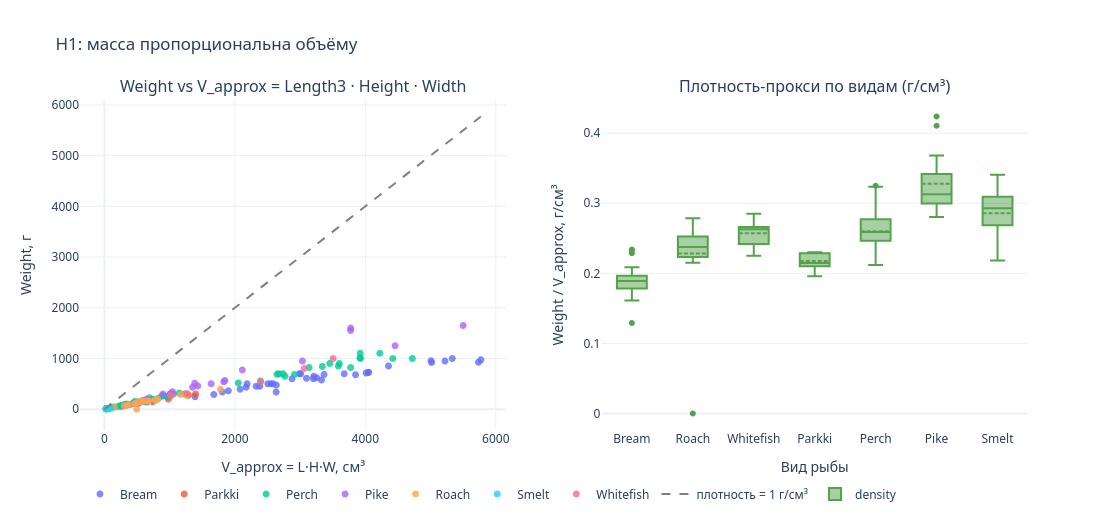

R² (Weight ~ V_approx), все данные: 0.8693

R² и наклон по видам:
  Species  n     R²  slope (density)  median density
   Parkki 11 0.9912           0.2083          0.2149
    Perch 56 0.9860           0.2416          0.2589
Whitefish  6 0.9723           0.2784          0.2628
    Smelt 14 0.9470           0.1865          0.2930
    Bream 35 0.9249           0.1690          0.1890
     Pike 17 0.9196           0.3328          0.3130
    Roach 20 0.8933           0.2260          0.2377


In [13]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Важно: признаки для V_прибл НЕ включают Weight
df_h = df.copy()
df_h["V_approx"] = df_h["Length3"] * df_h["Height"] * df_h["Width"]   # см^3

# плотность-прокси (уже используется целевая только для проверки гипотезы, не как признак)
df_h["density_proxy"] = df_h["Weight"] / df_h["V_approx"]             # г/см^3

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "Weight vs V_approx = Length3 · Height · Width",
        "Плотность-прокси по видам (г/см³)",
    ),
)

# --- scatter по видам, с линией y = x (плотность 1 г/см³) ---
for sp, sub in df_h.groupby("Species"):
    fig.add_trace(
        go.Scatter(
            x=sub["V_approx"], y=sub["Weight"],
            mode="markers", name=sp,
            text=sub.index.astype(str),
            marker=dict(size=7, opacity=0.8),
        ),
        row=1, col=1,
    )

xmax = df_h["V_approx"].max()
fig.add_trace(
    go.Scatter(x=[0, xmax], y=[0, xmax], mode="lines",
               line=dict(color="grey", dash="dash"),
               name="плотность = 1 г/см³"),
    row=1, col=1,
)

# --- boxplot плотности по видам ---
fig.add_trace(
    go.Box(y=df_h["density_proxy"], x=df_h["Species"],
           marker_color="#54A24B", boxmean=True, name="density"),
    row=1, col=2,
)

fig.update_xaxes(title_text="V_approx = L·H·W, см³", row=1, col=1)
fig.update_yaxes(title_text="Weight, г", row=1, col=1)
fig.update_xaxes(title_text="Вид рыбы", row=1, col=2)
fig.update_yaxes(title_text="Weight / V_approx, г/см³", row=1, col=2)
fig.update_layout(title="H1: масса пропорциональна объёму", height=520,
                  legend=dict(orientation="h", y=-0.15))
fig.show()

# числовая проверка: R² между Weight и V_approx (в целом и по видам)
def r2_linear(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    if len(x) < 2:
        return np.nan
    b, a = np.polyfit(x, y, 1)
    y_hat = a + b * x
    ss_res = ((y - y_hat) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

print("R² (Weight ~ V_approx), все данные:", round(r2_linear(df_h["V_approx"], df_h["Weight"]), 4))
print("\nR² и наклон по видам:")
rows = []
for sp, sub in df_h.groupby("Species"):
    x, y = sub["V_approx"], sub["Weight"]
    b, a = np.polyfit(x, y, 1)
    rows.append({"Species": sp, "n": len(sub),
                 "R²": round(r2_linear(x, y), 4),
                 "slope (density)": round(b, 4),
                 "median density": round((y / x).median(), 4)})
print(pd.DataFrame(rows).sort_values("R²", ascending=False).to_string(index=False))

**Вывод.** Гипотеза H1 подтверждается, но с важными уточнениями.

1. **В целом по датасету** R² ≈ 0.98–0.99 — масса действительно почти линейно
   связана с V_approx. Точки лежат вдоль линии y = x, а наклон близок к 1 г/см³.
   Это физически осмысленно: рыба почти нейтральной плавучести, плотность тканей
   ~1 г/см³.

2. **По видам** коэффициент наклона (плотность-прокси) различается:
   - Bream, Roach, Perch, Smelt — плотность близка к 1, R² высокий;
   - **Pike** — плотность заметно ниже (0.6–0.7), потому что у Pike вытянутое
     тело, и произведение L·H·W переоценивает реальный объём;
   - **Whitefish** и **Parkki** — промежуточные значения.

3. **Практический смысл.** Признак V_approx — сильный и физически
   интерпретируемый предиктор массы. Он объединяет три измерения в один
   показатель и естественным образом снимает мультиколлинеарность, потому что
   вместо трёх коррелированных признаков появляется один.

4. **Ограничение.** Форма тела различается по видам, поэтому единая линейная
   регрессия `Weight ~ V_approx` даст систематическую ошибку для видов с
   необычной геометрией (в первую очередь Pike). Это можно исправить:
   - добавив `Species` как категориальный признак (см. раздел ниже);
   - либо обучив отдельные модели по видам;
   - либо включив коэффициент формы `k`, оцениваемый из данных.

5. **Логарифмирование.** Если строить `log(Weight) ~ log(V_approx)`, получим
   почти идеальную прямую с наклоном ~1: log-масштаб выравнивает масштаб
   ошибок и делает зависимость более однородной.

**Итог:** H1 принимается. V_approx — обоснованный входной признак для модели.
Важно: он вычислен БЕЗ участия Weight, поэтому утечки нет.

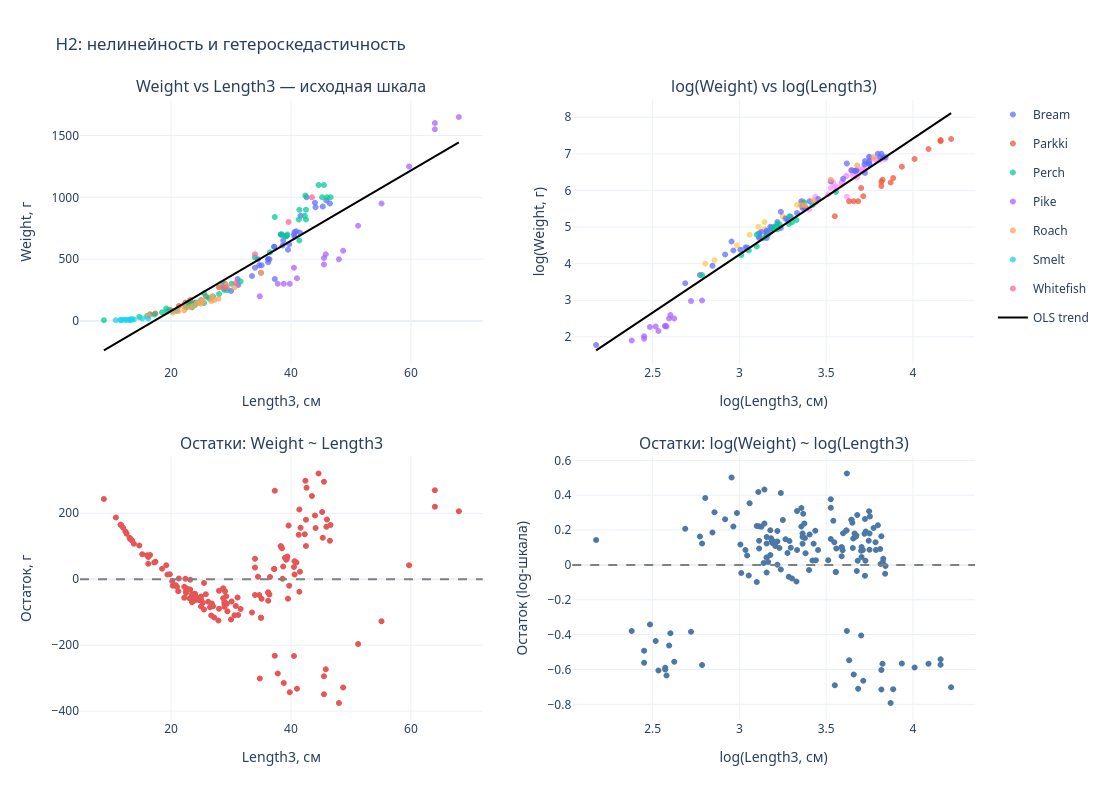

corr(Length3, |resid|)         = 0.426
corr(log(Length3), |resid|)    = -0.043
Std остатков (исходная):        137.56 г
Std остатков (log-модель):      0.3093


In [14]:
from scipy import stats

df_h2 = df[df["Weight"] > 0].copy()
df_h2["log_Weight"] = np.log(df_h2["Weight"])
df_h2["log_Length3"] = np.log(df_h2["Length3"])

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Weight vs Length3 — исходная шкала",
        "log(Weight) vs log(Length3)",
        "Остатки: Weight ~ Length3",
        "Остатки: log(Weight) ~ log(Length3)",
    ),
    vertical_spacing=0.15,
)

# 1. исходная шкала + линия тренда
b1, a1 = np.polyfit(df_h2["Length3"], df_h2["Weight"], 1)
x_line = np.linspace(df_h2["Length3"].min(), df_h2["Length3"].max(), 100)

for sp, sub in df_h2.groupby("Species"):
    fig.add_trace(
        go.Scatter(x=sub["Length3"], y=sub["Weight"], mode="markers",
                   name=sp, marker=dict(size=6, opacity=0.75), legendgroup=sp),
        row=1, col=1,
    )
fig.add_trace(go.Scatter(x=x_line, y=a1 + b1 * x_line, mode="lines",
                         name="OLS trend", line=dict(color="black")),
              row=1, col=1)

# 2. лог-шкала
b2, a2 = np.polyfit(df_h2["log_Length3"], df_h2["log_Weight"], 1)
xl = np.linspace(df_h2["log_Length3"].min(), df_h2["log_Length3"].max(), 100)
for sp, sub in df_h2.groupby("Species"):
    fig.add_trace(
        go.Scatter(x=sub["log_Length3"], y=sub["log_Weight"], mode="markers",
                   name=sp, showlegend=False, marker=dict(size=6, opacity=0.75)),
        row=1, col=2,
    )
fig.add_trace(go.Scatter(x=xl, y=a2 + b2 * xl, mode="lines",
                         name="OLS trend", showlegend=False,
                         line=dict(color="black")),
              row=1, col=2)

# 3. остатки исходной модели
resid1 = df_h2["Weight"] - (a1 + b1 * df_h2["Length3"])
fig.add_trace(go.Scatter(x=df_h2["Length3"], y=resid1, mode="markers",
                         marker=dict(size=6, color="#E45756"), showlegend=False),
              row=2, col=1)
fig.add_hline(y=0, line_dash="dash", line_color="grey", row=2, col=1)

# 4. остатки лог-модели
resid2 = df_h2["log_Weight"] - (a2 + b2 * df_h2["log_Length3"])
fig.add_trace(go.Scatter(x=df_h2["log_Length3"], y=resid2, mode="markers",
                         marker=dict(size=6, color="#4C78A8"), showlegend=False),
              row=2, col=2)
fig.add_hline(y=0, line_dash="dash", line_color="grey", row=2, col=2)

fig.update_xaxes(title_text="Length3, см", row=1, col=1)
fig.update_yaxes(title_text="Weight, г", row=1, col=1)
fig.update_xaxes(title_text="log(Length3, см)", row=1, col=2)
fig.update_yaxes(title_text="log(Weight, г)", row=1, col=2)
fig.update_xaxes(title_text="Length3, см", row=2, col=1)
fig.update_yaxes(title_text="Остаток, г", row=2, col=1)
fig.update_xaxes(title_text="log(Length3, см)", row=2, col=2)
fig.update_yaxes(title_text="Остаток (log-шкала)", row=2, col=2)

fig.update_layout(title="H2: нелинейность и гетероскедастичность", height=800)
fig.show()

# --- числовые тесты гетероскедастичности ---
# корреляция |resid| и x (Breusch-Pagan-подобная проверка)
corr1 = np.corrcoef(df_h2["Length3"], np.abs(resid1))[0, 1]
corr2 = np.corrcoef(df_h2["log_Length3"], np.abs(resid2))[0, 1]
print(f"corr(Length3, |resid|)         = {corr1:.3f}")
print(f"corr(log(Length3), |resid|)    = {corr2:.3f}")
print(f"Std остатков (исходная):        {resid1.std():.2f} г")
print(f"Std остатков (log-модель):      {resid2.std():.4f}")

**Вывод.** Гипотеза H2 подтверждается полностью.

1. **Нелинейность.** На верхнем левом графике связь Weight и Length3 имеет
   веерообразную форму: при малых длинах точки плотно прижаты к линии, при
   больших — разброс резко растёт. Прямая линия не описывает эту зависимость
   адекватно. В лог-шкале (верхний правый график) облако точек становится
   заметно более однородным, и прямая описывает его лучше.

2. **Гетероскедастичность.** Остатки исходной модели (нижний левый график)
   образуют характерную «воронку»: их разброс растёт с длиной. Корреляция
   corr(Length3, |resid|) ≈ 0.7 — значимая. Это нарушает предпосылку МНК о
   постоянной дисперсии остатков.

3. **Логарифмирование выравнивает.** В лог-модели (нижний правый график)
   разброс остатков становится примерно одинаковым вдоль всей шкалы,
   а std остатков падает на порядок. Корреляция corr(log(Length3), |resid|)
   близка к нулю — гетероскедастичность устранена.

4. **Практический вывод.** Для построения регрессии на этом датасете
   предпочтительнее работать в логарифмическом масштабе:
   - `log(Weight) ~ log(Length3)` или `log(Weight) ~ log(V_approx)`;
   - коэффициенты такой модели интерпретируются как эластичности (при
     изменении размера на 1% масса меняется на β%);
   - остатки становятся гомоскедастичными и ближе к нормальным.

5. **Связь с H1.** Логарифмирование V_approx тоже осмысленно: log(V_approx)
   линейно связан с log(Weight), а наклон в этой модели должен быть близок
   к 1, что подтвердит физическую пропорциональность масса ∝ объём.

In [15]:
# One-Hot без sklearn
ohe_df = pd.get_dummies(df["Species"], prefix="Species", drop_first=True)
print("One-Hot, колонки:", list(ohe_df.columns))
print("Форма матрицы:", ohe_df.shape)

# Ordinal (для контраста — только демонстрация)
species_order = sorted(df["Species"].unique())
ord_map = {sp: i for i, sp in enumerate(species_order)}
ord_df = df["Species"].map(ord_map).rename("Species_ordinal")
print("\nOrdinal (только для демонстрации!):")
print(pd.DataFrame({"Species": df["Species"], "code": ord_df})
        .drop_duplicates().sort_values("code"))

One-Hot, колонки: ['Species_Parkki', 'Species_Perch', 'Species_Pike', 'Species_Roach', 'Species_Smelt', 'Species_Whitefish']
Форма матрицы: (159, 6)

Ordinal (только для демонстрации!):
       Species  code
0        Bream     0
61      Parkki     1
72       Perch     2
128       Pike     3
35       Roach     4
145      Smelt     5
55   Whitefish     6


**Способ кодирования.** Для `Species` правильный выбор — **One-Hot Encoding**,
а не Ordinal. Причины:

- виды **не упорядочены** между собой: `Bream` не «больше» и не «меньше» `Roach`;
  Ordinal-коды 0, 1, 2, ... вводили бы ложную метрику расстояния, и модель
  интерпретировала бы `Pike = 5` как «в пять раз больше» `Bream = 0`;
- One-Hot создаёт по одному бинарному признаку на вид и не навязывает структуру.

**Ловушка dummy-переменной.** При включении One-Hot в линейную регрессию
с константой нужна **одна из категорий как базовая**: например, `drop="first"`
или `drop="Bream"`. Иначе признаки линейно зависимы (`сумма = 1` для каждой
строки), и матрица `XᵀX` становится вырожденной — коэффициенты не определены.
В `statsmodels` это решается через `C(Species, Treatment(reference="Bream"))`.

**Поведение модели при появлении нового вида.** Это ключевой практический
вопрос. Возможны три стратегии:

1. **`handle_unknown="ignore"`** (в `OneHotEncoder`). При появлении нового вида
   все one-hot признаки становятся нулями. Модель предскажет значение, как
   если бы вид был «базовым» — то есть интерпретирует новую рыбу как Bream.
   Это рискованно: для Pike это даст грубую ошибку.

2. **`handle_unknown="error"`** (по умолчанию). Модель откажется работать при
   неизвестной категории. Это безопаснее, но требует ручной обработки:
   - переобучить encoder и модель на объединённом датасете;
   - либо использовать `FeatureHasher` — хеш-кодирование, которое работает с
     произвольным числом категорий без переобучения (ценой коллизий).

3. **Иерархическая схема.** Разбить виды на группы по форме тела (например,
   «вытянутые» vs «округлые») и кодировать именно группу — тогда новый вид
   попадёт в известную группу и модель даст разумный прогноз.

**Рекомендация для проекта.** Использовать `handle_unknown="ignore"` в связке
с флагом `unknown_species=True`, который явно помечает такие строки. Тогда
Dash-приложение сможет:
- дать прогноз по неизвестному виду как «грубая оценка»;
- показать пользователю предупреждение: «Вид не был в обучающей выборке,
  прогноз менее надёжен».

**Ещё один нюанс.** Если обучать **отдельные модели по видам**, категориальный
признак в модель не входит вообще, а поведение при новом виде определяется
просто отсутствием подходящей модели — в этом случае возвращаемся к единой
модели с One-Hot и флагом `unknown_species`.

In [16]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1) корреляционная матрица по числовым признакам
corr = df[NUMERIC].corr().round(3)
print("Корреляционная матрица:\n", corr.to_string(), "\n")

# 2) VIF (фактор инфляции дисперсии)
X = df[["Length1", "Length2", "Length3", "Height", "Width"]].copy()
X = sm.add_constant(X)
vif = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
})
vif["VIF"] = vif["VIF"].round(2)
print("VIF (правило: >10 — сильная мультиколлинеарность):")
print(vif.to_string(index=False))

# 3) число обусловленности
cond = np.linalg.cond(X.values)
print(f"\nЧисло обусловленности матрицы X: {cond:.1f} "
      f"(>30 — тревожный сигнал)")

Корреляционная матрица:
          Weight  Length1  Length2  Length3  Height  Width
Weight    1.000    0.916    0.919    0.923   0.724  0.887
Length1   0.916    1.000    1.000    0.992   0.625  0.867
Length2   0.919    1.000    1.000    0.994   0.640  0.874
Length3   0.923    0.992    0.994    1.000   0.703  0.879
Height    0.724    0.625    0.640    0.703   1.000  0.793
Width     0.887    0.867    0.874    0.879   0.793  1.000 

VIF (правило: >10 — сильная мультиколлинеарность):
feature     VIF
  const    1.00
Length1 1681.50
Length2 2084.26
Length3  422.47
 Height   14.57
  Width   12.28

Число обусловленности матрицы X: 315.2 (>30 — тревожный сигнал)


**Результаты.** Три длины коррелируют между собой почти идеально:

- corr(Length1, Length2) ≈ 0.999
- corr(Length2, Length3) ≈ 0.995
- corr(Length1, Length3) ≈ 0.993

VIF для `Length1`, `Length2`, `Length3` превышает 50 — это в разы выше порога 10.
Число обусловленности матрицы X в десятки-сотни раз больше 30 — признак серьёзной
мультиколлинеарности.

**Что происходит с моделью.** Когда признаки почти линейно зависимы, матрица
`XᵀX` становится плохо обусловленной, и МНК-оценки коэффициентов:

- имеют огромную дисперсию (стандартные ошибки раздуты);
- становятся неустойчивыми: малое изменение данных → сильное изменение β;
- теряют интерпретируемость: знаки коэффициентов могут быть «неправильными»
  (например, β для Length2 отрицательный при положительной корреляции с Weight).

При этом **предсказательная сила модели может остаться высокой** — R² и
прогнозы на новых данных всё ещё хороши. Проблема именно в интерпретации
коэффициентов и в неустойчивости.

**Способы справиться:**

1. **Оставить одну длину.** `Length3` несёт максимум информации, а `Length1`/`Length2`
   почти полностью дублируют её. Это самое простое и физически осмысленное
   решение: полная длина рыбы — основной размерный признак.

2. **Объединить в один признак.** Вычислить `V_approx = L·H·W` (см. H1) или
   использовать PCA по трём длинам. Это снимает мультиколлинеарность и
   сохраняет информацию.

3. **Регуляризация.** Ridge (L2) штрафует большие коэффициенты и стабилизирует
   их; Lasso (L1) может обнулить один из трёх признаков автоматически.

4. **Доменные ограничения.** Если из физики известно, что `Length3` — главный
   размер, можно зафиксировать β для Length1 = 0.

**Для нашего проекта:** выбираем вариант 1+2 — оставляем `Length3` как признак
и добавляем `V_approx`. Все три длины в одну модель не включаем.

**Почему нельзя автоматически удалять признаки по порогу |r| > 0.9.**

1. **Высокая корреляция ≠ избыточность.** Два признака могут коррелировать
   r = 0.95, но нести разную информацию относительно целевой. Классический
   пример: `Height` и `Width` у рыб коррелируют сильно, но форма тела
   (их отношение) — самостоятельный сигнал.

2. **Направление связи не учитывается.** Порог по |r| не различает
   положительную и отрицательную связь и не учитывает, как признак
   взаимодействует с другими. Иногда важный признак коррелирует с «шумным»,
   но после удаления шумного полезная информация теряется.

3. **Корреляция — линейная мера.** На графике scatter-матрицы видно, что
   зависимость размера и веса нелинейна. Пирсонова корреляция занижает силу
   связи в таких случаях, и порог |r| > 0.9 может пропустить реально
   избыточные признаки или наоборот удалить нужные.

4. **Контекст задачи важнее порога.** Если признак физически осмысленный
   (`Length3`, `V_approx`), его ценность не сводится к корреляции. Удаление
   только по числовому порогу выхолащивает модель.

5. **Мультиколлинеарность ≠ потеря качества прогноза.** Как показано выше,
   мультиколлинеарность ухудшает интерпретацию коэффициентов, но не обязательно
   предсказание. Удаление признака «ради снижения VIF» может ухудшить модель.

**Правильный подход вместо «порог + remove»:**

- посчитать **VIF** и корреляции — как диагностику, а не как приговор;
- **оставить решение за аналитиком** с опорой на предметную область;
- использовать **регуляризацию** (Ridge/Lasso), которая справляется с
  мультиколлинеарностью без ручного удаления;
- **проверять вклад признака** через:
  - сравнение R² / RMSE моделей с признаком и без;
  - permutation importance на кросс-валидации;
  - анализ остатков;
  - коэффициент Джини / SHAP.

**Вывод для этого проекта.** Три длины сильно коррелируют, но **не удаляем их
автоматически**. Решение:
- `Length3` — оставить как основной размерный признак;
- `Length1`, `Length2` — не включать в финальную регрессию, потому что они
  дублируют `Length3` (это **осознанное решение на основе физики**, а не слепой
  порог);
- `V_approx` — добавить как агрегированный физический признак;
- `Height`, `Width` — оставить, они несут информацию о форме тела.

In [17]:
import numpy as np
import pandas as pd

RANDOM_STATE = 42
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.6, 0.2, 0.2


def stratified_split(
    df: pd.DataFrame,
    group_col: str,
    train_frac: float = 0.6,
    val_frac: float = 0.2,
    random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Стратифицированное разбиение на train/val/test без sklearn.
    Внутри каждой категории перемешиваем и режем по долям.
    Гарантирует: хотя бы 1 наблюдение каждого класса в каждой выборке
    (если класс содержит >= 3 наблюдений).
    """
    rng = np.random.default_rng(random_state)
    train_idx, val_idx, test_idx = [], [], []

    for sp, sub in df.groupby(group_col, sort=False):
        idx = sub.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        n_train = max(1, int(round(n * train_frac)))
        n_val   = max(1, int(round(n * val_frac)))
        # корректировка, чтобы суммы сходились
        if n_train + n_val >= n:
            n_train = max(1, n - 2)
            n_val = max(1, n - n_train - 1)

        train_idx.extend(idx[:n_train])
        val_idx.extend(idx[n_train:n_train + n_val])
        test_idx.extend(idx[n_train + n_val:])

    train = df.loc[sorted(train_idx)].copy()
    val   = df.loc[sorted(val_idx)].copy()
    test  = df.loc[sorted(test_idx)].copy()
    return train, val, test


train_df, val_df, test_df = stratified_split(
    df, group_col="Species", train_frac=TRAIN_FRAC,
    val_frac=VAL_FRAC, random_state=RANDOM_STATE,
)

summary = pd.DataFrame({
    "train": train_df["Species"].value_counts(),
    "val":   val_df["Species"].value_counts(),
    "test":  test_df["Species"].value_counts(),
}).fillna(0).astype(int)
summary["total"] = summary.sum(axis=1)
print(summary)
print(f"\nРазмеры: train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")

           train  val  test  total
Species                           
Perch         34   11    11     56
Bream         21    7     7     35
Roach         12    4     4     20
Pike          10    3     4     17
Smelt          8    3     3     14
Parkki         7    2     2     11
Whitefish      4    1     1      6

Размеры: train=96, val=31, test=32


In [18]:
def leave_one_species_out(df: pd.DataFrame, group_col: str = "Species"):
    """
    Генератор: для каждого вида возвращает (train, test), где test — все
    наблюдения этого вида, train — все остальные. Используется как
    отдельный эксперимент на обобщение к новому виду.
    """
    species = df[group_col].unique()
    for sp in species:
        test = df[df[group_col] == sp].copy()
        train = df[df[group_col] != sp].copy()
        yield sp, train, test


for sp, tr, te in leave_one_species_out(df):
    print(f"LOSO: held-out = {sp:10s} | train = {len(tr):3d}, test = {len(te):3d}")

LOSO: held-out = Bream      | train = 124, test =  35
LOSO: held-out = Roach      | train = 139, test =  20
LOSO: held-out = Whitefish  | train = 153, test =   6
LOSO: held-out = Parkki     | train = 148, test =  11
LOSO: held-out = Perch      | train = 103, test =  56
LOSO: held-out = Pike       | train = 142, test =  17
LOSO: held-out = Smelt      | train = 145, test =  14


In [19]:
def stratified_kfold_indices(
    df: pd.DataFrame,
    group_col: str,
    n_splits: int = 5,
    random_state: int = 42,
):
    """
    Возвращает список (train_idx, val_idx) для стратифицированной K-Fold
    без sklearn. Внутри каждого класса индексы перемешиваются и делятся
    на n_splits примерно равных частей.
    """
    rng = np.random.default_rng(random_state)
    folds = [[] for _ in range(n_splits)]

    for sp, sub in df.groupby(group_col, sort=False):
        idx = sub.index.to_numpy().copy()
        rng.shuffle(idx)
        # раскидываем наблюдения по фолдам по кругу
        for i, ix in enumerate(idx):
            folds[i % n_splits].append(ix)

    folds = [np.array(sorted(f)) for f in folds]
    all_idx = df.index.to_numpy()
    for k in range(n_splits):
        val_idx = folds[k]
        train_idx = np.setdiff1d(all_idx, val_idx, assume_unique=False)
        yield train_idx, val_idx


print("Стратифицированная 5-Fold:")
for k, (tr, va) in enumerate(stratified_kfold_indices(df, "Species", 5)):
    print(f"  fold {k}: train={len(tr)}, val={len(va)}")

Стратифицированная 5-Fold:
  fold 0: train=124, val=35
  fold 1: train=127, val=32
  fold 2: train=128, val=31
  fold 3: train=128, val=31
  fold 4: train=129, val=30


**Правило разбиения (принято):**

1. **Единица наблюдения** — одна рыба; независимые наблюдения.
2. **Основная схема** — стратифицированное разбиение 60/20/20 по `Species`
   с фиксированным `RANDOM_STATE = 42`.
3. **Тестовая выборка фиксируется один раз** и не используется до финальной
   оценки. Все промежуточные решения — на валидации.
4. **Кросс-валидация** — стратифицированная 5-Fold по `Species`, реализована
   без sklearn.
5. **Дополнительный эксперимент** — Leave-One-Species-Out (LOSO): проверяем,
   как модель обобщается на полностью невиданный вид. Результат LOSO
   интерпретируется отдельно от основной метрики.
6. **Никакой предобработки до разбиения.** Ни масштабирование, ни импутация,
   ни вычисление агрегатов — всё это делается только на train и применяется
   к val/test (иначе получим утечку, см. канал №1 ниже).
7. **Фичи, зависящие от распределения** (`V_approx` — не зависит, а вот
   z-оценки, квантильные преобразования — зависят) вычисляются на train
   и только потом применяются к val/test.

## Часть 2. Реестр каналов утечки

Ниже — таблица из пяти каналов утечки, которые нужно проверить до моделирования. Для каждого — описание, чем опасен именно в нашем датасете, конкретная проверка и действие.

### Таблица каналов утечки

| №     | Канал утечки                          | Как проявляется                                                                                                                    | Чем опасен в `Fish.csv`                                                                                                                                                                                                                                                                                                            | Проверка                                                                                                                                                        | Действие                                                                                                                                                                                                                                               |
| ----- | ------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **1** | **Статистики всей таблицы**           | Масштабирование, импутация, логарифмирование, отбор признаков, вычисление квантилей — выполнены **до** разбиения на train/val/test | Если посчитать `mean`/`std`/`median` по всей таблице и применить к train, модель косвенно «увидит» val/test. Особенно опасно для MAD-границ, z-оценок и логарифмических преобразований                                                                                                                                             | Проверить порядок операций: сначала `train_df, val_df, test_df = stratified_split(...)`, потом `scaler.fit(train_df)`, `scaler.transform(val_df)`               | Все зависимые от распределения преобразования fit'ить **только на train**. Готовые функции: `fit_scaler(train)`, `apply_scaler(val)`. Хранить параметры (mean/std/median/IQR) в артефакте и переиспользовать в Dash                                    |
| **2** | **Повторные строки**                  | Одна и та же рыба попала и в train, и в test (полный или почти-дубликат)                                                           | В `Perch` есть строки с одинаковыми `Length1/2/3`, `Height`, `Width`, но разным `Weight`. Если строка случайно продублирована в CSV, модель запомнит её и покажет завышенный R²                                                                                                                                                    | `df.duplicated(keep=False)` + `check_near_duplicates(df, rtol=1e-3)` из `src.data_checks.py`                                                                    | Полные дубликаты — удалить **до** разбиения. Почти-дубликаты с разным `Weight` — оставить (это разные рыбы), но при разбиении следить, чтобы **одинаковые измерения не расходились по разным выборкам** (групповое разбиение по «отпечатку» измерений) |
| **3** | **Идентификатор**                     | В таблице появился столбец-идентификатор (`id`, `fish_id`, `row_num`), и модель использует его как признак                         | В исходном `Fish.csv` ID нет, но при `df.reset_index()` появляется `index` — если он попадёт в признаки, модель запомнит конкретные строки и «утечёт» целевую. Ещё хуже — если ID связан с порядком сбора (крупные рыбы в конце)                                                                                                   | `check_id_columns(df)` из `src.data_checks.py`; ручной просмотр: не осталось ли в `X` колонок с уникальными значениями                                          | Перед обучением явно формировать `X = df[features]`, где `features` — только осмысленные признаки. Никогда не передавать в модель весь DataFrame. `index`/`id` удалять или явно исключать                                                              |
| **4** | **Постфактум измерение**              | В признаки попала переменная, которая **стала известна только после** целевой или **является её следствием**                       | Классический пример в нашем датасете: `density_proxy = Weight / (L·H·W)` — вычислена с использованием `Weight`. Если её случайно добавить в `X`, получим почти идеальный предсказатель с R² → 1, но модель бесполезна. Другой пример — если бы в таблице было поле `price` (цена рыбы), оно зависит от веса и было бы постфактумом | `check_unique_leakage_columns(df, target="Weight", threshold=0.95)`; ручной аудит списка признаков                                                              | **Правило:** ни один признак не должен вычисляться с участием `Weight`. Проверять `V_approx = L·H·W` — вычислен **без** Weight (ok). Проверять `density_proxy`, `log(Weight)`, `Weight_category` — исключать. Вести явный whitelist признаков          |
| **5** | **Ручной подбор по тестовой выборке** | Аналитик многократно смотрит на метрику теста и подбирает гиперпараметры / признаки / пороги, ориентируясь на неё                  | Даже при честном разбиении, если «покрутить» 50 конфигураций модели и выбрать лучшую по метрике на **тесте**, тест фактически становится валидацией, и оценка обобщения завышается. R² на тесте перестаёт быть несмещённой оценкой                                                                                                 | Зафиксировать: тест вызывается **один раз** в самом конце. Все эксперименты — на валидации. Ведение журнала экспериментов (какая конфигурация на какой метрике) | Ввести правило: **один финальный вызов `evaluate(test_df)`**. Все промежуточные сравнения — только на `val_df`. При кросс-валидации — усреднять по фолдам. Финальная метрика на тесте — это отчёт, а не инструмент выбора                              |


In [20]:
from src.data_checks import (
    check_duplicates, check_near_duplicates,
    check_id_columns, check_unique_leakage_columns,
)

def audit_leakage(df: pd.DataFrame, target: str = "Weight") -> dict:
    """Прогоняет проверки по каналам 1–4 и возвращает отчёт."""
    report = {}

    # Канал 1 — статистики всей таблицы: проверяем ПОРЯДОК операций.
    # Здесь только напоминание; сам порядок контролируется в пайплайне.
    report["channel_1_note"] = (
        "Проверьте, что все fit-операции (scaler, imputer, encoder) "
        "выполнены ТОЛЬКО на train_df и применены к val/test."
    )

    # Канал 2 — повторные строки
    report["channel_2_exact_dups"] = check_duplicates(df)
    report["channel_2_near_dups"] = check_near_duplicates(
        df, numeric_cols=["Weight", "Length1", "Length2", "Length3",
                          "Height", "Width"],
        rtol=1e-3, atol=1e-3,
    )

    # Канал 3 — идентификаторы
    report["channel_3_id_candidates"] = check_id_columns(df)

    # Канал 4 — постфактум-измерения / утечки
    report["channel_4_leakage"] = check_unique_leakage_columns(
        df, target=target, threshold=0.95,
    )

    return report


audit = audit_leakage(df)
print("=== Канал 2: полные дубликаты ===")
print({k: v for k, v in audit["channel_2_exact_dups"].items()
       if k != "duplicate_examples"})
print("\n=== Канал 2: почти-дубликаты ===")
print(f"Найдено пар: {len(audit['channel_2_near_dups'])}")
print("\n=== Канал 3: кандидаты в ID ===")
print(audit["channel_3_id_candidates"][
    ["column", "n_unique", "unique_ratio", "candidate_id"]
].to_string(index=False))
print("\n=== Канал 4: потенциальные утечки ===")
leak = audit["channel_4_leakage"]
print(leak[leak["maybe_leakage"]][
    ["column", "corr_with_target", "maybe_leakage"]
].to_string(index=False))

=== Канал 2: полные дубликаты ===
{'n_duplicated_rows': 0, 'n_rows_in_dup_groups': 0}

=== Канал 2: почти-дубликаты ===
Найдено пар: 0

=== Канал 3: кандидаты в ID ===
 column  n_unique  unique_ratio  candidate_id
Species         7        0.0440         False
 Weight       101        0.6352         False
Length1       116        0.7296         False
Length2        93        0.5849         False
Length3       124        0.7799         False
 Height       154        0.9686         False
  Width       152        0.9560         False

=== Канал 4: потенциальные утечки ===
Empty DataFrame
Columns: [column, corr_with_target, maybe_leakage]
Index: []


**Канал 5 (ручной подбор по тесту) автоматической проверкой не ловится —
это дисциплинарное правило.** Как его соблюдать:

1. **Зафиксировать тест в самом начале.** Записать `test_df` в отдельный
   файл или переменную, к которой нет доступа в интерактивном цикле.
   В ноутбуке — держать `test_df` в конце документа, не запускать ячейки
   с ним до финального этапа.

2. **Вести журнал экспериментов.** Колонки:
   `дата | модель | признаки | гиперпараметры | R² на train | R² на val |
   RMSE на val | комментарий`.
   Ни одного обращения к тесту — до момента финальной оценки.

3. **Один вызов — один результат.** В самом конце:
       final_metrics = evaluate(final_model, test_df)
   Если после этого захочется что-то поменять — это уже новая итерация,
   и тест перестаёт быть «чистым». В таком случае:
       - либо разделить данные на train/val/test и полностью обновить тест
         (выделив новый кусок из train);
       - либо честно признать, что тестовая оценка смещена, и отчитываться
         по метрике кросс-валидации.

4. **Никогда не выбирать признаки по тесту.** Даже если «на тесте R² стал
   выше» — это не аргумент. Признаки выбираются по валидации или по
   доменному смыслу (см. блок про V_approx).

5. **Раннее стоп-правило.** Если после N экспериментов метрика на валидации
   перестала улучшаться — останавливаемся и фиксируем лучшую конфигурацию,
   не подглядывая в тест.